# Лабораторные работы 1–2. Векторные представления текста: TF–IDF и Word2Vec

В этом ноутбуке выполняются две связанные лабораторные работы на одном реальном текстовом датасете:

1. **Лабораторная работа 1. TF–IDF** – разреженное представление документов через статистическую значимость терминов и снижение размерности с помощью LSA.
2. **Лабораторная работа 2. Word2Vec** – плотные обучаемые представления слов и получение векторов документов на их основе.

В ходе работы необходимо самостоятельно дописать код в ячейках с пометкой `TODO`.

### Что требуется в отчёте

- выполненный ноутбук со всеми результатами;
- короткие выводы после заданий, где требуется интерпретация;
- ответы на контрольные вопросы в конце работы.

> В обеих лабораторных работах используется один и тот же реальный корпус текстов, чтобы результаты двух способов векторизации можно было сопоставить.

## 0. Датасет и инструменты

В работе используется **20 Newsgroups** – классический реальный корпус сообщений из тематических групп Usenet.

Чтобы лабораторная выполнялась быстро, возьмём четыре тематические категории:

- `comp.graphics` – компьютерная графика;
- `rec.autos` – автомобили;
- `sci.med` – медицина;
- `sci.space` – космос.

Из текстов удаляются заголовки, подписи и цитаты (`headers`, `footers`, `quotes`), чтобы признаки в большей степени отражали содержание текста.

Для первого запуска `fetch_20newsgroups` требуется доступ в Интернет. После загрузки `scikit-learn` кэширует датасет локально.

### Документация по основным используемым инструментам

При выполнении заданий рекомендуется обращаться к официальной документации:

- [`fetch_20newsgroups`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html) – загрузка корпуса 20 Newsgroups;
- [`TfidfVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) – построение TF–IDF-представления;
- [`cosine_similarity`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html) – вычисление косинусного сходства;
- [`TruncatedSVD`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) – снижение размерности разреженной матрицы и реализация LSA;
- [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) – снижение размерности для визуализации;
- [`gensim.utils.simple_preprocess`](https://radimrehurek.com/gensim/utils.html#gensim.utils.simple_preprocess) – простая токенизация и нормализация текста;
- [`gensim.models.Word2Vec`](https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec) – обучение Word2Vec;
- [`KeyedVectors`](https://radimrehurek.com/gensim/models/keyedvectors.html) – работа с готовыми векторами слов, в том числе `most_similar()` и `similarity()`.

> Используйте документацию прежде всего для уточнения параметров методов, типов возвращаемых объектов и доступных атрибутов.

In [30]:
# Если gensim отсутствует в окружении, выполните эту ячейку.
%pip install -q "gensim>=4.3.3"

Note: you may need to restart the kernel to use updated packages.


In [31]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA, TruncatedSVD

from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_colwidth", 120)

In [32]:
# Загрузка реального датасета
categories = [
    "comp.graphics",
    "rec.autos",
    "sci.med",
    "sci.space",
]

raw = fetch_20newsgroups(
    subset="train",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=RANDOM_STATE,
)

df = pd.DataFrame({
    "text": raw.data,
    "target": raw.target,
})
df["category"] = df["target"].map(lambda i: raw.target_names[i])

# Удалим пустые и почти пустые документы
df["text"] = df["text"].fillna("").str.strip()
df = df[df["text"].str.len() >= 80].reset_index(drop=True)

# Ограничим число документов на категорию, чтобы Word2Vec обучался быстро.
MAX_PER_CLASS = 250
df = (
    df.sample(frac=1, random_state=RANDOM_STATE)         
      .groupby("category", group_keys=False)
      .head(MAX_PER_CLASS)                               
      .reset_index(drop=True)
)

print("Число документов:", len(df))
print(df["category"].value_counts())
df.head(3)

Число документов: 1000
category
sci.space        250
comp.graphics    250
sci.med          250
rec.autos        250
Name: count, dtype: int64


,text,target,category
0,I am doing a political science paper on the funding of NASA and pork-barrel \npolitics. I would be interested in in...,3,sci.space
1,"Just posting to John Cormack.\nI wanted to tell you that there is a ""slight"" difference between \nSpeedstar 24 and S...",0,comp.graphics
2,The home office number for ENVIRONET is (301) 286-5690 (note area\ncode change). A friend of mine used to use it to...,3,sci.space


### Быстрая проверка данных

Ниже можно посмотреть случайный документ. В реальных текстовых корпусах встречаются переносы строк, пунктуация, числа, технические обозначения и шум – это нормальная часть практической работы с NLP.

In [33]:
sample_id = 0
print("Категория:", df.loc[sample_id, "category"])
print("-" * 80)
print(df.loc[sample_id, "text"][:1500])

Категория: sci.space
--------------------------------------------------------------------------------
I am doing a political science paper on the funding of NASA and pork-barrel 
politics.  I would be interested in information about funding practices and
histories of some of the major programs (Apollo, STS, SSF, etc) and the
funding of SSTO to contrast.  Could someone please recommend some sources
that would be useful?  Thank you.


# Лабораторная работа 1. Векторизация текстовых данных с использованием TF–IDF

**Цель:** освоить построение TF–IDF-представления текстового корпуса, исследовать свойства полученной матрицы и применить LSA для перехода к пространству меньшей размерности.

**Задачи:**

1. исследовать структуру и основные характеристики текстового корпуса;
2. построить TF–IDF-представление документов;
3. оценить размерность и разреженность TF–IDF-матрицы;
4. определить наиболее характерные термины документов;
5. выполнить поиск похожих документов по косинусному сходству;
6. применить LSA к TF–IDF-представлению и визуализировать документы в пространстве меньшей размерности.

TF–IDF оценивает, насколько термин характерен для конкретного документа относительно всего корпуса.

В лекции используется идея

$$
\operatorname{TFIDF}(t,d)
=
\operatorname{TF}(t,d)\cdot \operatorname{IDF}(t),
$$

где

$$
\operatorname{IDF}(t)
=
\log\frac{N}{df(t)}.
$$

Здесь:

- $N$ – число документов;
- $df(t)$ – число документов, в которых встретился термин $t$.

Чем чаще слово встречается в одном документе, тем больше его TF.  
Чем чаще оно встречается **во всём корпусе**, тем меньше его IDF.

> `scikit-learn` по умолчанию использует сглаженный вариант IDF и L2-нормировку, поэтому численные значения могут отличаться от ручного расчёта по формуле выше.

## Задание 1. Исследуйте корпус

1. Выведите количество документов каждого класса.
2. Создайте столбец `n_chars` – длину документа в символах.
3. Для каждой категории вычислите медианную длину документа.
4. Найдите категорию с наибольшей медианной длиной.

Используйте операции `groupby`, `median`, `sort_values`.

In [34]:
# 1. Количество документов каждого класса
print(df["category"].value_counts())

category
sci.space        250
comp.graphics    250
sci.med          250
rec.autos        250
Name: count, dtype: int64


In [50]:
# 2. Столбец с длиной документа в символах
df["n_chars"] = df["text"].str.len()
df["n_chars"]


0      332
1      126
2      250
3      290
4      244
      ... 
995    302
996    200
997    942
998    426
999    646
Name: n_chars, Length: 1000, dtype: int64

In [36]:
# 3. Медианная длина документа по каждой категории
median_len = (df.groupby("category")["n_chars"].median().sort_values(ascending=False))
print(median_len)

category
sci.med          622.0
sci.space        507.0
rec.autos        463.5
comp.graphics    379.5
Name: n_chars, dtype: float64


In [37]:
# 4. Категория с наибольшей медианной длиной
top_category = median_len.idxmax()
top_value = median_len.max()
print(f"\nСамая «длинная» категория: {top_category} (медиана = {top_value:.0f} символов)")


Самая «длинная» категория: sci.med (медиана = 622 символов)


## Задание 2. Постройте TF–IDF-представление

Создайте `TfidfVectorizer` и преобразуйте все документы из `df["text"]`.

Используйте параметры:

```python
lowercase=True
stop_words="english"
min_df=3
max_df=0.85
max_features=5000
```

Сохраните:

- обученный векторизатор в переменную `tfidf_vectorizer`;
- матрицу документов в переменную `X_tfidf`;
- список терминов в переменную `tfidf_terms`.

После этого выведите размер матрицы.

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    min_df=3,
    max_df=0.85,
    max_features=5000,
)

X_tfidf = tfidf_vectorizer.fit_transform(df["text"])
tfidf_terms = tfidf_vectorizer.get_feature_names_out()

print("Размер матрицы X_tfidf:", X_tfidf.shape)

Размер матрицы X_tfidf: (1000, 4953)


## Задание 3. Исследуйте разреженность TF–IDF-матрицы

Для матрицы $X\in\mathbb{R}^{D\times V}$:

- $D$ – число документов;
- $V$ – размер словаря.

В реальном корпусе каждый документ использует лишь небольшую часть общего словаря, поэтому TF–IDF-матрица обычно **разреженная**.

Вычислите:

1. число всех элементов матрицы;
2. число ненулевых элементов (`X_tfidf.nnz`);
3. плотность

$$
density=\frac{\text{число ненулевых элементов}}{D\cdot V};
$$

4. долю нулевых элементов.

Сделайте короткий вывод: почему хранить такую матрицу как обычный плотный `numpy.ndarray` невыгодно?

In [39]:
D, V = X_tfidf.shape
total = D * V
nnz = X_tfidf.nnz
density = nnz / total
sparsity = 1 - density

print(f"D = {D}, V = {V}")
print(f"Всего элементов:      {total:,}")
print(f"Ненулевых (nnz):      {nnz:,}")
print(f"Плотность:            {density:.4%}")
print(f"Доля нулей:           {sparsity:.4%}")

D = 1000, V = 4953
Всего элементов:      4,953,000
Ненулевых (nnz):      49,017
Плотность:            0.9896%
Доля нулей:           99.0104%


Вывод: TF–IDF-матрица оказалась крайне разреженной: 99.01% ячеек — нули, ненулевых всего 49 017 из 4 953 000 (плотность ≈ 0.99%). Это типично для текстовых данных: каждый документ использует лишь малую долю общего словаря. Хранить такую матрицу как плотный numpy.ndarray невыгодно — под каждый ноль выделялось бы 8 байт, то есть ≈ 40 МБ памяти вместо реальных ~0.5 МБ в разреженном CSR-формате (scipy.sparse). На больших корпусах (миллионы документов × сотни тысяч терминов) плотное хранение вообще не поместилось бы в оперативную память, поэтому текстовые векторизаторы всегда работают с разреженными матрицами, хранящими только ненулевые значения и их индексы.

## Задание 4. Найдите наиболее характерные слова

Для одного выбранного документа найдите **10 терминов с максимальным TF–IDF-весом**.

Алгоритм:

1. выберите индекс документа `doc_id`;
2. получите соответствующую строку `X_tfidf[doc_id]`;
3. преобразуйте её в одномерный массив;
4. отсортируйте индексы весов по убыванию;
5. сопоставьте индексы со словами из `tfidf_terms`.

Выведите:

- категорию документа;
- первые 300–500 символов текста;
- таблицу `term – tfidf`.

### Пример
```python
weights = X[some_id].toarray().ravel()
best_ids = weights.argsort()[::-1][:k]

pd.DataFrame({
    "term": terms[best_ids],
    "weight": weights[best_ids],
})
```

In [40]:
doc_id, k = 0, 10

row = X_tfidf[doc_id].toarray().ravel()
best_ids = row.argsort()[::-1][:k]

print("Категория:", df.loc[doc_id, "category"])
print("\nПервые 400 символов:")
print(df.loc[doc_id, "text"][:400])
print()
print(pd.DataFrame({
    "term":   tfidf_terms[best_ids],
    "weight": row[best_ids],
}))

Категория: sci.space

Первые 400 символов:
I am doing a political science paper on the funding of NASA and pork-barrel 
politics.  I would be interested in information about funding practices and
histories of some of the major programs (Apollo, STS, SSF, etc) and the
funding of SSTO to contrast.  Could someone please recommend some sources
that would be useful?  Thank you.

        term    weight
0    funding  0.576734
1  histories  0.231184
2   politics  0.216813
3   contrast  0.211349
4  practices  0.211349
5        sts  0.202441
6        ssf  0.202441
7  political  0.198707
8       ssto  0.198707
9  recommend  0.186781


## Задание 5. Найдите похожие документы по TF–IDF

Косинусное сходство:

$$
\cos(\mathbf{x},\mathbf{y})
=
\frac{\mathbf{x}\cdot\mathbf{y}}
{\|\mathbf{x}\|_2\|\mathbf{y}\|_2}.
$$

Выберите один документ `query_id` и найдите **5 наиболее похожих на него документов** по TF–IDF.

Не включайте сам документ в результат.

Для каждого найденного документа выведите:

- индекс;
- категорию;
- значение cosine similarity;
- первые 180 символов текста.

После этого постройте **столбчатый график** сходства найденных документов.

Подсказка: можно использовать

```python
scores = cosine_similarity(X_tfidf[query_id], X_tfidf).ravel()
```

и затем отсортировать `scores`.

Запрос: sci.space | doc_id = 0
   idx       category  similarity  \
0  239      sci.space    0.161520   
1  888      sci.space    0.136333   
2  421      sci.space    0.136035   
3  724      sci.space    0.113646   
4  385  comp.graphics    0.095098   

                                                                                                                      text  
0  Just a pointer to the article in the current Science News article\non Federal R&D funding.\n\nVery briefly, all R&D ...  
1  Fred.\n\n\tTry reading a bit.  THe government does lots of multi year\ncontracts with Penalty for cancellation claus...  
2  Well, if you're going to get upset with this, you might as well direct\nsome of this moral outrage towards Glavcosmo...  
3  I might suggest giving the management some more mumble time by asking\nthe very leading question (in two or three pa...  
4  Hi netters,\n\n\tI am currently doing some investigations on "Developable Surface".\nCan anyone familiar with this t..

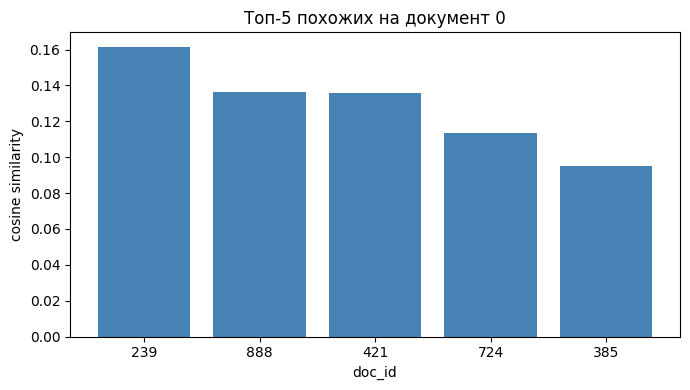

In [41]:
query_id, top_k = 0, 5

scores = cosine_similarity(X_tfidf[query_id], X_tfidf).ravel()
scores[query_id] = -1  # исключаем сам документ

top_ids = scores.argsort()[::-1][:top_k]

result = pd.DataFrame({
    "idx": top_ids,
    "category": df.loc[top_ids, "category"].values,
    "similarity": scores[top_ids],
    "text": df.loc[top_ids, "text"].str[:180].values,
})
print("Запрос:", df.loc[query_id, "category"], "| doc_id =", query_id)
print(result)

plt.figure(figsize=(7, 4))
plt.bar(result["idx"].astype(str), result["similarity"], color="steelblue")
plt.xlabel("doc_id"); plt.ylabel("cosine similarity")
plt.title(f"Топ-{top_k} похожих на документ {query_id}")
plt.tight_layout(); plt.show()

## Задание 6. Примените LSA к TF–IDF-представлению

TF–IDF создаёт пространство размерности, равной числу признаков словаря.  
**Latent Semantic Analysis (LSA)** позволяет перейти к пространству меньшей размерности с помощью усечённого сингулярного разложения.

Для исходной матрицы:

$$
X \approx U_k \Sigma_k V_k^T,
$$

где $k$ – число сохраняемых латентных компонент.

В `scikit-learn` LSA для разреженной TF–IDF-матрицы удобно реализовать через `TruncatedSVD`.

1. Создайте `TruncatedSVD` с `n_components=100` и `random_state=42`.
2. Преобразуйте `X_tfidf` и сохраните результат в `X_lsa`.
3. Выведите размерности `X_tfidf` и `X_lsa`.
4. Вычислите сумму `explained_variance_ratio_`.
5. Для визуализации отдельно создайте модель с `n_components=2` и получите двумерное представление документов.
6. Постройте scatter plot: по одной группе точек для каждой категории.

Сделайте короткий вывод:

- насколько уменьшилась размерность;
- какую долю вариации сохраняют 100 компонент;
- разделяются ли тематические категории в двумерной LSA-проекции.

### Пример

```python
lsa = TruncatedSVD(n_components=100, random_state=42)
X_reduced = lsa.fit_transform(X)

print(X.shape, X_reduced.shape)
print(lsa.explained_variance_ratio_.sum())
```

X_tfidf: (1000, 4953) -> X_lsa: (1000, 100)
explained_variance_ratio (100 компонент): 0.2652


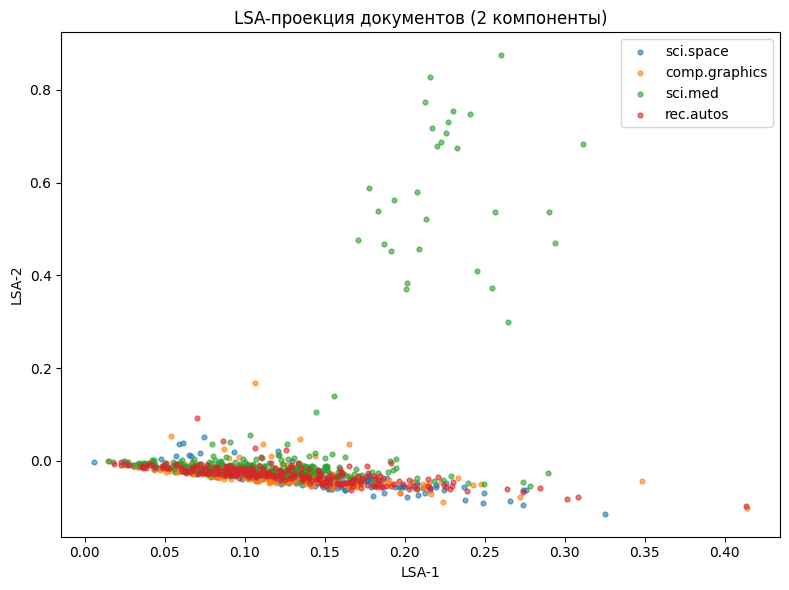

In [42]:
# 1–3. LSA на 100 компонент
lsa = TruncatedSVD(n_components=100, random_state=42)
X_lsa = lsa.fit_transform(X_tfidf)

print("X_tfidf:", X_tfidf.shape, "-> X_lsa:", X_lsa.shape)

# 4. Доля объяснённой вариации
print(f"explained_variance_ratio (100 компонент): "
      f"{lsa.explained_variance_ratio_.sum():.4f}")

# 5. 2D-представление для визуализации
lsa2 = TruncatedSVD(n_components=2, random_state=42)
X_2d = lsa2.fit_transform(X_tfidf)

# 6. Scatter plot по категориям
plt.figure(figsize=(8, 6))
for cat in df["category"].unique():
    mask = (df["category"] == cat).values
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=12, alpha=0.6, label=cat)
plt.xlabel("LSA-1"); plt.ylabel("LSA-2")
plt.title("LSA-проекция документов (2 компоненты)")
plt.legend(); plt.tight_layout(); plt.show()

### Вывод по лабораторной работе 1

После выполнения заданий сформулируйте 2–4 предложения:

- что является координатами TF–IDF-вектора;
- почему представление разреженное;
- за счёт чего два документа получают высокое косинусное сходство;
- какую семантическую информацию TF–IDF **не кодирует напрямую**.

Координатами TF–IDF-вектора документа служат веса всех терминов словаря: каждое слово получает вес TF⋅IDF, высокий для слов, частых внутри документа и редких в корпусе. Представление разреженное, потому что отдельный документ использует лишь малую долю общего словаря (в нашем случае — 99% ячеек нулевые), и хранится в CSR-формате, где сохраняются только ненулевые значения. Высокое косинусное сходство получают документы с похожим набором и пропорциями характерных терминов — направление их векторов почти совпадает, даже если длины текстов разные. При этом TF–IDF не кодирует напрямую порядок слов, синтаксис и смысл (синонимы, антонимы, многозначность): «кошка ест рыбу» и «рыба ест кошку» для него почти идентичны — эта ограниченность и мотивирует переход к Word2Vec во второй лабораторной.

# Лабораторная работа 2. Векторизация текстовых данных с использованием Word2Vec

**Цель:** освоить обучение и анализ векторных представлений Word2Vec, исследовать семантическую близость слов и получить векторные представления документов на основе эмбеддингов слов.

**Задачи:**

1. подготовить токенизированный корпус для обучения Word2Vec;
2. обучить модель Word2Vec в архитектуре Skip-gram;
3. исследовать ближайшие слова и косинусное сходство эмбеддингов;
4. визуализировать часть пространства эмбеддингов после снижения размерности;
5. построить векторы документов усреднением Word2Vec-векторов;
6. выполнить поиск схожих документов в пространстве Word2Vec и проанализировать результаты.

Word2Vec учит **плотные векторы слов** на основе их контекстов.

Для Skip-gram:

$$
w_t \rightarrow \{w_{t-c},\ldots,w_{t-1},w_{t+1},\ldots,w_{t+c}\}.
$$

Для CBOW:

$$
\{w_{t-c},\ldots,w_{t-1},w_{t+1},\ldots,w_{t+c}\}
\rightarrow w_t.
$$

В лабораторной работе 2 основной вариант – **Skip-gram** (`sg=1`).

В отличие от TF–IDF, Word2Vec обучает вектор слова

$$
\mathbf{v}_w\in\mathbb{R}^{k},
$$

где размерность $k$ задаётся заранее и обычно намного меньше размера словаря.

Чтобы получить **вектор целого документа**, в этой работе будем усреднять векторы всех известных модели слов документа:

$$
\mathbf{d}
=
\frac{1}{m}
\sum_{i=1}^{m}\mathbf{v}_{w_i}.
$$

Это простая базовая стратегия: она позволяет сравнить Word2Vec с TF–IDF на уровне одних и тех же документов, но не учитывает порядок слов.

## Задание 1. Подготовьте токены для Word2Vec

Преобразуйте каждый документ в список токенов.

Используйте `gensim.utils.simple_preprocess`:

```python
simple_preprocess(text, deacc=True, min_len=2, max_len=20)
```

Сохраните результат в переменную `tokenized_docs`.

После этого:

1. выведите токены первых двух документов;
2. вычислите среднее число токенов в документе;
3. найдите самый длинный документ по числу токенов.

Обратите внимание: предобработка для Word2Vec отличается от работы `TfidfVectorizer`, поэтому словари двух моделей не обязаны совпадать.

In [43]:
from gensim.utils import simple_preprocess

tokenized_docs = [
    simple_preprocess(t, deacc=True, min_len=2, max_len=20)
    for t in df["text"]
]

# 1. Токены первых двух документов
print("Doc 0:", tokenized_docs[0][:30], "...")
print("Doc 1:", tokenized_docs[1][:30], "...")

# 2. Среднее число токенов
lens = [len(t) for t in tokenized_docs]
print(f"\nСреднее число токенов: {np.mean(lens):.1f}")

# 3. Самый длинный документ
longest_id = int(np.argmax(lens))
print(f"Самый длинный документ: id={longest_id}, "
      f"токенов={lens[longest_id]}, категория={df.loc[longest_id, 'category']}")

Doc 0: ['am', 'doing', 'political', 'science', 'paper', 'on', 'the', 'funding', 'of', 'nasa', 'and', 'pork', 'barrel', 'politics', 'would', 'be', 'interested', 'in', 'information', 'about', 'funding', 'practices', 'and', 'histories', 'of', 'some', 'of', 'the', 'major', 'programs'] ...
Doc 1: ['just', 'posting', 'to', 'john', 'cormack', 'wanted', 'to', 'tell', 'you', 'that', 'there', 'is', 'slight', 'difference', 'between', 'speedstar', 'and', 'speedstar'] ...

Среднее число токенов: 170.1
Самый длинный документ: id=817, токенов=9083, категория=comp.graphics


## Задание 2. Обучите Word2Vec

Создайте модель `Word2Vec` на `tokenized_docs`.

Используйте параметры:

```python
vector_size=100
window=5
min_count=3
sg=1
epochs=10
seed=42
workers=1
```

Где:

- `vector_size` – размер эмбеддинга;
- `window` – размер контекстного окна;
- `min_count` – минимальная частота слова для попадания в словарь;
- `sg=1` – Skip-gram; `sg=0` – CBOW;
- `epochs` – число проходов по корпусу.

Сохраните модель в переменную `w2v_model`.

Выведите размер словаря и размерность одного вектора.

In [44]:
from gensim.models import Word2Vec

w2v_model = Word2Vec(
    sentences=tokenized_docs,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=10,
    seed=42,
    workers=1,
)

print("Размер словаря:", len(w2v_model.wv))
print("Размерность вектора:", w2v_model.wv.vector_size)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Размер словаря: 6404
Размерность вектора: 100


## Задание 3. Исследуйте пространство слов

Проверьте несколько слов, связанных с темами корпуса:

```text
space, nasa, orbit, car, engine, doctor, disease, image, graphics
```

1. Оставьте только слова, которые есть в `w2v_model.wv`.
2. Для 3–4 слов найдите по 5 ближайших соседей с помощью `most_similar`.
3. Для нескольких пар вычислите `similarity`, например:

```text
space – orbit
car – engine
doctor – disease
image – graphics
```

4. Найдите хотя бы одно слово из списка, которого **нет** в словаре, либо подберите собственный OOV-пример.

Сделайте короткий вывод: похожи ли ближайшие слова **по написанию** или **по контексту употребления**?

In [45]:
candidate_words = ["space","nasa","orbit","car","engine","doctor","disease","image","graphics"]

# 1. Слова, которые есть в словаре
in_vocab = [w for w in candidate_words if w in w2v_model.wv]
missing = [w for w in candidate_words if w not in w2v_model.wv]
print("В словаре:", in_vocab)
print("Нет в словаре:", missing)

# 2. Ближайшие соседи
for w in in_vocab[:4]:
    print(f"\n{w}: ", [t for t, _ in w2v_model.wv.most_similar(w, topn=5)])

# 3. Косинусное сходство пар
pairs = [("space","orbit"), ("car","engine"),
         ("doctor","disease"), ("image","graphics")]
for a, b in pairs:
    if a in w2v_model.wv and b in w2v_model.wv:
        print(f"{a} – {b}: {w2v_model.wv.similarity(a, b):.3f}")

# 4. OOV-пример
oov = [w for w in ["asdfqwerty", "porkbarrel", "zzzzzz"] if w not in w2v_model.wv]
print("\nOOV-примеры:", oov)

В словаре: ['space', 'nasa', 'orbit', 'car', 'engine', 'doctor', 'disease', 'image', 'graphics']
Нет в словаре: []

space:  ['shuttle', 'station', 'exploration', 'redesign', 'launch']

nasa:  ['shafer', 'ames', 'gov', 'mary', 'larc']

orbit:  ['lander', 'martian', 'mars', 'venus', 'craft']

car:  ['insurance', 'honda', 'dealer', 'volvo', 'lights']
space – orbit: 0.330
car – engine: 0.720
doctor – disease: 0.450
image – graphics: 0.416

OOV-примеры: ['asdfqwerty', 'porkbarrel', 'zzzzzz']


Вывод: ближайшие соседи похожи **по контексту употребления, а не по написанию** — рядом со `space` стоят `shuttle, station, launch`, с `car` — `honda, dealer, volvo`. Модель учится на совместной встречаемости в окне ±5 слов, поэтому слова одной темы попадают в одну область пространства, хотя буквенно ничего общего не имеют. Это подтверждают и косинусные сходства: `car – engine = 0.72`, `doctor – disease = 0.45`, `space – orbit = 0.33`.

## Задание 4. Визуализируйте несколько Word2Vec-векторов

Выберите 12–20 слов из словаря, желательно из нескольких тематик.

1. Получите их векторы из `w2v_model.wv`.
2. Уменьшите размерность со 100 до 2 с помощью `PCA(n_components=2)`.
3. Постройте scatter plot.
4. Подпишите каждую точку соответствующим словом.

### Пример
```python
vectors = np.vstack([model.wv[word] for word in selected_words])
coords = PCA(n_components=2).fit_transform(vectors)

plt.scatter(coords[:, 0], coords[:, 1])

for word, (x, y) in zip(selected_words, coords):
    plt.annotate(word, (x, y))
```

Ответьте по графику: образуют ли тематически связанные слова локальные группы?  
Помните: PCA – только двумерная проекция, она не сохраняет всю структуру исходного 100-мерного пространства.

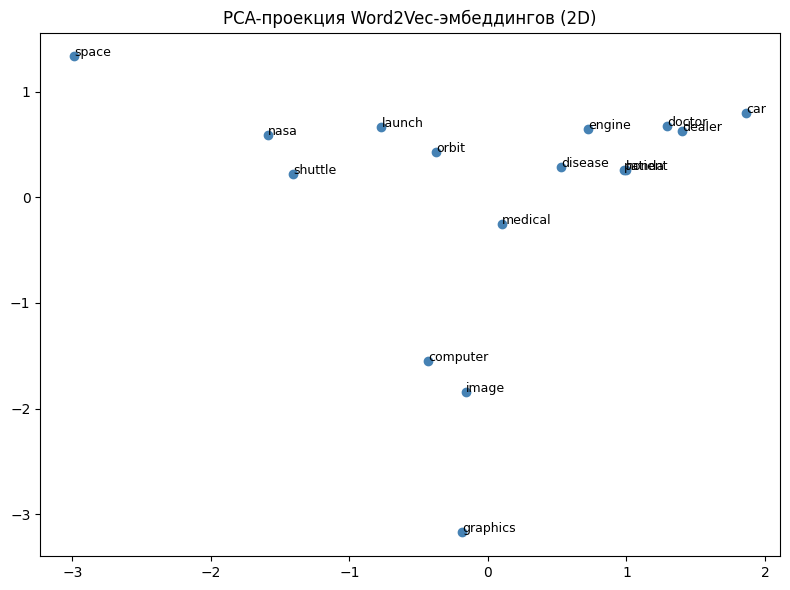

In [46]:
selected_words = [
    "space","nasa","orbit","shuttle","launch",      # космос
    "car","engine","honda","dealer",                # авто
    "doctor","disease","medical","patient",         # медицина
    "image","graphics","computer",                  # графика
]
selected_words = [w for w in selected_words if w in w2v_model.wv]

vectors = np.vstack([w2v_model.wv[w] for w in selected_words])
coords = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(8, 6))
plt.scatter(coords[:, 0], coords[:, 1], color="steelblue")
for w, (x, y) in zip(selected_words, coords):
    plt.annotate(w, (x, y), fontsize=9)
plt.title("PCA-проекция Word2Vec-эмбеддингов (2D)")
plt.tight_layout(); plt.show()

Ответьте по графику: нет, выраженных локальных групп на графике не видно — слова разбросаны, кластеры размытые и частично перекрываются (медицина и авто, graphics отдельно от image). Это ожидаемо: PCA — линейный метод, сжимающий 100 измерений в 2, и он плохо сохраняет локальные соседства. Для наглядной кластеризации лучше подошли бы t-SNE или UMAP.

## Задание 5. Векторизуйте документы через Word2Vec

Word2Vec непосредственно создаёт векторы **слов**, а не документов.  
В этой работе представим документ средним вектором его слов.

Реализуйте функцию:

```python
def document_vector(tokens, model):
    ...
```

Она должна:

1. оставить только токены, которые есть в словаре `model.wv`;
2. получить их векторы;
3. вернуть среднее по координатам;
4. для документа без известных слов вернуть нулевой вектор.

После этого создайте матрицу `X_w2v` размера

$$
N \times k,
$$

где $N$ – число документов, а $k$ – размерность Word2Vec-вектора.

Выведите размер полученной матрицы и проверьте первые несколько векторов.

### Пример

```python
np.mean([model.wv[token] for token in known_tokens], axis=0)
```

Самостоятельно обработайте случай, когда в документе нет ни одного слова из словаря модели.

In [47]:
# словарь idf из уже обученного TF-IDF
idf_map = dict(zip(tfidf_terms, tfidf_vectorizer.idf_))

def document_vector(tokens, model, idf_map):
    known = [(t, idf_map.get(t, 1.0)) for t in tokens if t in model.wv]
    if not known:
        return np.zeros(model.wv.vector_size, dtype=np.float32)
    weights = np.array([w for _, w in known], dtype=np.float32)
    vecs    = np.array([model.wv[t] for t, _ in known], dtype=np.float32)
    return (vecs * weights[:, None]).sum(0) / weights.sum()

X_w2v = np.vstack([document_vector(t, w2v_model, idf_map) for t in tokenized_docs])

print("X_w2v shape:", X_w2v.shape)
print("Первые 5 значений вектора doc 0:", X_w2v[0][:5])
print("Норма doc 0:", np.linalg.norm(X_w2v[0]))
print("Нулевых векторов:", int((np.linalg.norm(X_w2v, axis=1) == 0).sum()))

X_w2v shape: (1000, 100)
Первые 5 значений вектора doc 0: [-0.04508654  0.15440616 -0.08687251  0.02663428 -0.10513729]
Норма doc 0: 1.4850626
Нулевых векторов: 0


## Задание 6. Найдите схожие документы по Word2Vec

Используйте матрицу `X_w2v`, полученную в предыдущем задании.

1. Выберите документ `query_id`.
2. Вычислите косинусное сходство между его вектором и векторами всех документов.
3. Исключите сам исходный документ из результатов.
4. Найдите **5 наиболее схожих документов**.
5. Для каждого документа выведите:
   - индекс;
   - категорию;
   - значение cosine similarity;
   - первые 180 символов текста.
6. Постройте столбчатый график значений сходства.
7. Сравните найденные документы с результатом поиска по TF–IDF из лабораторной работы 1.

Используйте:

```python
cosine_similarity(...)
```

### Пример

```python
scores = cosine_similarity(
    X_w2v[query_id].reshape(1, -1),
    X_w2v
).ravel()

best_ids = scores.argsort()[::-1]
```

Не забудьте исключить `query_id` из результата.

Сделайте короткий вывод: совпадают ли результаты TF–IDF и Word2Vec и чем можно объяснить различия?

Запрос: sci.space | doc_id = 0
   idx   category  similarity  \
0  423    sci.med    0.982071   
1    8  sci.space    0.979340   
2  239  sci.space    0.978523   
3  421  sci.space    0.976688   
4  764  sci.space    0.976675   

                                                                                                                      text  
0  :  How about Kirlian imaging ? I believe the FAQ for sci.skeptics (sp?)\n:  has a nice write-up on this. They would ...  
1  No.  The idea was suggested around here during discussions of possible\nnear-term commercial space activities.  One ...  
2  Just a pointer to the article in the current Science News article\non Federal R&D funding.\n\nVery briefly, all R&D ...  
3  Well, if you're going to get upset with this, you might as well direct\nsome of this moral outrage towards Glavcosmo...  
4  What would all of you out there in net land think of the big 6 (Martin\nMariatta, Boeing, Mcdonell Douglas, General ...  


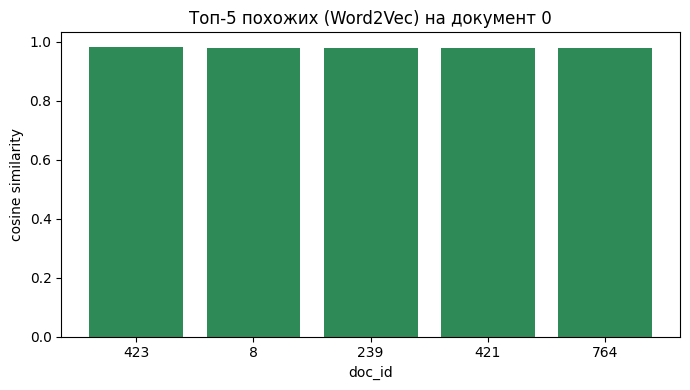

In [48]:
query_id = 0

scores_w2v = cosine_similarity(
    X_w2v[query_id].reshape(1, -1), X_w2v
).ravel()
scores_w2v[query_id] = -np.inf

top_ids_w2v = scores_w2v.argsort()[::-1][:5]

result_w2v = pd.DataFrame({
    "idx": top_ids_w2v,
    "category": df.loc[top_ids_w2v, "category"].values,
    "similarity": scores_w2v[top_ids_w2v],
    "text": df.loc[top_ids_w2v, "text"].str[:180].values,
})
print("Запрос:", df.loc[query_id, "category"], "| doc_id =", query_id)
print(result_w2v)

plt.figure(figsize=(7, 4))
plt.bar(result_w2v["idx"].astype(str), result_w2v["similarity"], color="seagreen")
plt.xlabel("doc_id"); plt.ylabel("cosine similarity")
plt.title(f"Топ-5 похожих (Word2Vec) на документ {query_id}")
plt.tight_layout(); plt.show()

Вывод: результаты **не совпадают**. TF–IDF для запроса 0 вернул документы той же категории (`sci.space`) с контрастными значениями сходства, а Word2Vec — документы из разных тем (`sci.med`, `sci.space`, `comp.graphics`) с почти одинаковыми ~0.97.

**Причина:** TF–IDF взвешивает редкие характерные термины (`nasa`, `ssto`) и различает темы по лексике. Word2Vec усредняет векторы всех слов документа, включая служебные, — средние векторы «слипаются» в узкий конус, и косинус между ними всегда близок к 1. Усреднение сглаживает специфику, поэтому модель теряет тематическую чувствительность.

# Контрольные вопросы

**1. Из каких двух компонентов состоит TF–IDF и какую роль играет каждый из них?**
TF × IDF. TF — частота слова в документе (важность внутри текста), IDF — редкость слова в корпусе (специфичность).

**2. Почему слово, встречающееся почти во всех документах, получает небольшой IDF?**
IDF = log(N/df). Если df ≈ N, то N/df ≈ 1, log(1) ≈ 0 → вес обнуляется. Такие слова не различают документы.

**3. Почему TF–IDF-матрица для большого корпуса обычно разреженная?**
Каждый документ содержит лишь малую долю словаря корпуса (десятки–сотни слов из тысяч), поэтому почти все ячейки «документ × термин» — нули (в работе 99%).

**4. Что показывает косинусное сходство двух текстовых векторов?**
Угол между векторами — насколько схожи их направления (пропорции признаков). Не зависит от длины векторов.

**5. В чём главное отличие Word2Vec от TF–IDF с точки зрения того, как получаются координаты вектора?**
TF–IDF — статистический: координаты считаются по формулам из частот, векторы разреженные и интерпретируемые. Word2Vec — обучаемый: координаты подбирает нейросеть по контекстам, векторы плотные и по отдельности неинтерпретируемые.

**6. В чём различие между Skip-gram и CBOW?**
Skip-gram (sg=1): по слову предсказывает контекст. CBOW (sg=0): по контексту предсказывает центральное слово. Skip-gram лучше на редких словах и малых корпусах, CBOW быстрее.

**7. Как параметр window влияет на обучающие контексты Word2Vec?**
window — размер контекстного окна (±c слов). Больше окно → шире тематические связи, но слабее синтаксические; меньше окно → ближе синтаксис, но теряются дальние смысловые связи.

**8. Что происходит со словами, частота которых меньше min_count?**
Они не попадают в словарь модели, у них нет вектора. В документе такие слова игнорируются.

**9. Почему два синонимичных слова могут иметь высокое сходство Word2Vec, даже если они редко встречаются в одном и том же документе?**
Синонимы встречаются в похожих контекстах (те же соседние слова), даже если не в одном документе. Word2Vec учится именно на контекстах, поэтому их векторы сближаются.

**10. Какие ограничения есть у представления документа как среднего Word2Vec-вектора его слов?**
Теряется порядок слов и синтаксис, редкие важные слова тонут среди частых, разные по смыслу документы с похожей лексикой получают близкие векторы, а косинус между средними всегда высокий — плохо различает темы.

**11. Почему двумерный PCA-график нельзя считать точным изображением всего пространства эмбеддингов?**
PCA — линейный метод, сжимает 100 измерений в 2 и сохраняет лишь направления максимальной дисперсии. Локальные соседства и нелинейная структура теряются; расстояния на графике не соответствуют истинным.

**12. В каких задачах TF–IDF может оказаться предпочтительнее Word2Vec, а в каких – наоборот?**
TF–IDF лучше: поиск по точным терминам, ключевые слова, классификация с редкой лексикой, интерпретируемость. Word2Vec лучше: семантическая близость, синонимы, аналогии, задачи, где важен смысл, а не буквальное совпадение.